In [2]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
## %pip install openpyxl
# 2. Load datasets
a = pd.read_csv("sales_data_sample.csv", encoding='latin1')
b = pd.read_excel("sales_data_sample.xlsx")
c = pd.read_json("csvjson.json")

In [4]:
# 3. Explore data
print(a.head())
a.info()
print(a.isnull().sum())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [5]:
# 4. Combine datasets
df = pd.concat([a, b, c])
df = df.drop_duplicates()
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,"C/ Moralzarzal, 86",,Madrid,,28034,Spain,EMEA,Freyre,Diego,Small
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,Torikatu 38,,Oulu,,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,"C/ Moralzarzal, 86",,Madrid,,28034,Spain,EMEA,Freyre,Diego,Medium
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,1 rue Alsace-Lorraine,,Toulouse,,31000,France,EMEA,Roulet,Annette,Small


In [6]:
# 5. Data cleaning
df = df.dropna(subset=['SALES'])
df = df.fillna('Unknown')

In [7]:
# 6. Data transformation
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])
df['YEAR'] = df['ORDERDATE'].dt.year
df['MONTH'] = df['ORDERDATE'].dt.month


In [8]:
# 7. Data analysis
print("Total Sales:", df['SALES'].sum())
print("Average Sales:", df['SALES'].mean())
print(df.groupby('PRODUCTLINE')['SALES'].sum())

Total Sales: 28058683.86
Average Sales: 3562.5550863382427
PRODUCTLINE
Classic Cars        11035212.50
Motorcycles          3272361.57
Planes               2680456.12
Ships                1954143.22
Trains                648436.89
Trucks and Buses     3181140.20
Vintage Cars         5286933.36
Name: SALES, dtype: float64


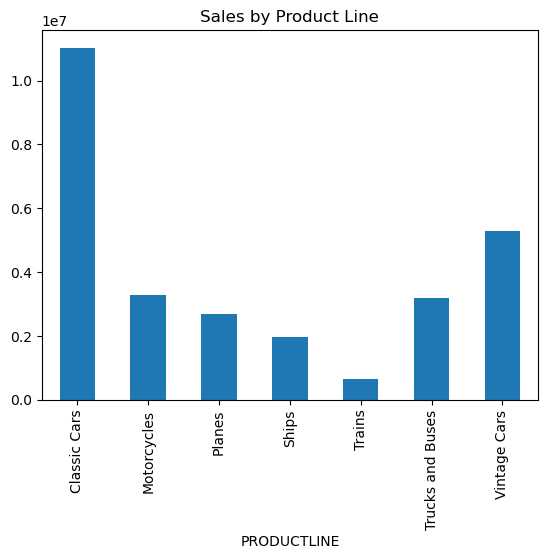

In [9]:
# 8. Visualization5
df.groupby('PRODUCTLINE')['SALES'].sum().plot(kind='bar')
plt.title("Sales by Product Line")
plt.show()


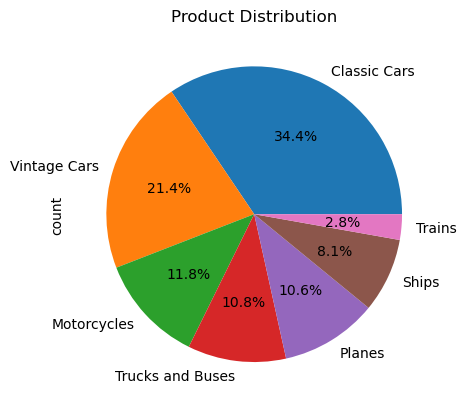

In [10]:
df['PRODUCTLINE'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Product Distribution")
plt.show()


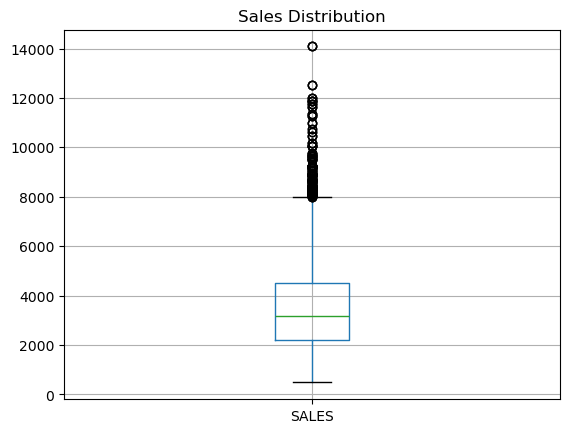

In [11]:
df.boxplot(column='SALES')
plt.title("Sales Distribution")
plt.show()